| Name           | Student ID   | Work Percentage |
|----------------|--------------|-----------------|
| name student 1 | id student 1 | 50%             |
| name student 2 | id student 2 | 50%             |

# Task 1: Correlation of Future Orientation Index and Gross Domestic Product
## Tasks

In this exercise, we try to reproduce the findings of the article “Quantifying the Advantage of Looking Forward” http://www.nature.com/articles/srep00350.

According to the study, the GDP per capita of countries is positively correlated to how much their population searches in Google for the next year, relative to how much they search for the previous year.

This ratio is called the Future Orientation Index (FOI). So for example for the year 2017 the FOI can be calculated as: FOI = number of searches for the term “2018” / number of searches for the term “2016”.

You will do the following tasks:
1. Aquire World Bank Data
2. Calculate the Future Orientation Index in Google Trends
3. Test the correlation between GDP and FOI

### Install requirements. 

The following cell contains all the necessary dependencies needed for this task. If you run the cell everything will be installed.  
* [`wbgapi`](https://github.com/tgherzog/wbgapi) is a Python package which provides modern, pythonic access to the World Bank's data API. [Here](https://github.com/tgherzog/wbgapi) is the documentation of `wbgapi`.
* [`pandas`](https://pandas.pydata.org/docs/index.html) is a Python package for creating and working with tabular data. [Here](https://pandas.pydata.org/docs/reference/index.html) is the documentation of `pandas`.
* [`matplotlib`](https://matplotlib.org/) is a Python package for creating plots. [Here](https://matplotlib.org/stable/api/index.html) is the documentation of `matplotlib`.
* [`scipy`](https://scipy.org/) is a Python package with different algorithms for scientific computing. [Here](https://docs.scipy.org/doc/scipy/reference/index.html#scipy-api) is the documentation of `scipy`.

In [ ]:
! pip install wbgapi
! pip install pandas
! pip install matplotlib
! pip install scipy

### Import requirements
The cell below imports all necessary dependancies. Make sure they are installed (see cell above).

In [3]:
import wbgapi as wb
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 1 World Bank Data
## 1.1 Download WDI data

From the WDI we need three indicators:
* Gross Domestic Product (GDP) per capita corrected by the Purchase Power Parity (PPP in current or 2005 international $, `"NY.GDP.PCAP.PP.KD"`)
* The amount of Internet users (per 100 people, `"IT.NET.USER.ZS"`
* The total population (described as as "Population, Total", `"SP.POP.TOTL"`)

In the following code chunk, download all data (including extras) for all countries in year 2014 and save it as a pandas data frame. See [here](https://github.com/tgherzog/wbgapi#accessing-data) how to use the `data` subpackage of `wbgapi`. 

Hint: To remove aggregates (economic regions defined by the World Bank) and include only countries, use `skipAggs=True`.  
You can also rename the columns to make it easier to use.

In [4]:
# Your Code goes here!
WDIdf = wb.data.DataFrame(['NY.GDP.PCAP.PP.KD', 'SP.POP.TOTL', 'IT.NET.USER.ZS'],
             labels = True,time=2014, skipAggs=True)

WDIdf = WDIdf.rename(columns={"NY.GDP.PCAP.PP.KD": "GDP",
                              "SP.POP.TOTL": "population",
                              "IT.NET.USER.ZS": "internet_per_100"})
WDIdf


,Country,internet_per_100,GDP,population
economy,,,,
ZWE,Zimbabwe,16.364740,5081.134412,14207359.0
ZMB,Zambia,6.500000,3585.577485,15895315.0
YEM,"Yemen, Rep.",22.549999,NaN,30226309.0
PSE,West Bank and Gaza,53.665200,5990.426615,4173398.0
VIR,Virgin Islands (U.S.),50.070000,42853.898660,107882.0
...,...,...,...,...
AND,Andorra,86.099998,59929.244467,73737.0
ASM,American Samoa,NaN,NaN,53466.0
DZA,Algeria,29.500000,15073.762940,39205031.0


Now drop any row that has `NaN` for this you can use `pandas` [`dropna`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html) method.

In [5]:
# Your Code goes here!
WDIdf = WDIdf.dropna()
print(WDIdf)

                       Country  internet_per_100           GDP  population
economy                                                                   
ZWE                   Zimbabwe         16.364740   5081.134412  14207359.0
ZMB                     Zambia          6.500000   3585.577485  15895315.0
PSE         West Bank and Gaza         53.665200   5990.426615   4173398.0
VIR      Virgin Islands (U.S.)         50.070000  42853.898660    107882.0
VNM                   Viet Nam         41.000000   8751.882806  91679578.0
...                        ...               ...           ...         ...
AGO                     Angola         21.362341  11718.428683  27160769.0
AND                    Andorra         86.099998  59929.244467     73737.0
DZA                    Algeria         29.500000  15073.762940  39205031.0
ALB                    Albania         54.299999  13366.504095   2773767.0
AFG                Afghanistan          7.000000   3017.942544  32792523.0

[191 rows x 4 columns]


Next we want to filter our data just for the countries that have more than 5 million Internet users because for countries with less, we think the data is not sufficient to make a good statement. Keep in Mind that the Internet Users are per 100 people, so don't forget to take the population into account.  
You can create a new column with the actual number of internet users and then filter based on that.

For example in the dataset Austria has 80.995825 internet users per 100 people, while 8546356 people living in Austria. This means Austria has 6922191.55 internet users in total. The calculation for that is as follows:
$
\begin{align}
internet\_users = population \cdot \frac{internet\_user\_per\_100}{100}
\end{align}
$


In [6]:
# Your Code goes here!
WDIdf["internet_users"] = WDIdf["population"] * (WDIdf["internet_per_100"] / 100)
print(WDIdf.loc["AUT", "internet_users"])
WDIdf=WDIdf[WDIdf["internet_users"] > 5000000]
print(WDIdf)
print(len(WDIdf),"countries left")

6922191.546002782
                      Country  internet_per_100           GDP   population  \
economy                                                                      
VNM                  Viet Nam         41.000000   8751.882806   91679578.0   
UZB                Uzbekistan         35.500000   7344.443044   30222994.0   
USA             United States         73.000000  63026.877919  319257560.0   
GBR            United Kingdom         91.613301  49763.173880   64619000.0   
ARE      United Arab Emirates         90.400011  74145.117545    8059440.0   
...                       ...               ...           ...          ...   
AUT                   Austria         80.995825  60845.574398    8546356.0   
AUS                 Australia         84.000000  55489.068844   23475686.0   
ARG                 Argentina         64.699997  28200.815257   43024071.0   
AGO                    Angola         21.362341  11718.428683   27160769.0   
DZA                   Algeria         29.50000

# 2 The Future Orientation Index in Google Trends
Now that we have the GDP for all countries with more than 5 million Internet users, we want to get the number of times they searched for the years 2013 and 2015.
## 2.1 Download data from Google Trends

You can download the data from Google Trends following these steps:

1) Log out from your google account or set its language to English

2) Go to trends.google.com and search for 2013 

3) Add 2015 as a search term

4) Select custom time rage: full year: 2014

5) Set the region to “Worldwide”. You can also try with this link (it links to the google trends page with all settings from above applied): https://trends.google.com/trends/explore?date=2014-01-01%202014-12-31&q=2013,2015

6) Go to the map at “Compared breakdown by region” and tick on “include low search volume regions”

7) On the top right menu click the download button to get a geoMap.csv file


Load the .csv file in a pandas data frame. Notice in the file the first 3 Lines are actually only information (while the third is the header). You can skip these lines by using `skiprows=3` in `pd.read_csv`. Set the headers to `"Country", "G2013", "G2015"`, this can be done by the keyword argument `names` in `pd.read_csv`.

Now remove again all rows containing `NaN`.

All the percentage data is saved as a string containing the `%` symbol. You can remove this with `pandas` [`str.replace`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.replace.html) method and save them as integer with `pandas` [`astype`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html) method. Do this for column `G2013` and `G2015`.


In [7]:
# Your Code goes here!
GT = pd.read_csv("geoMap.csv", skiprows=3, names=["Country", "G2013", "G2015"])
GT = GT.dropna()
for col in ["G2013", "G2015"]:
    GT[col] = GT[col].str.replace("%", "").str.replace("<", "").astype(int)
GT.head()


,Country,G2013,G2015
Algeria,15%,7,78
Pakistan,15%,2,83
Cuba,12%,6,82
Vanuatu,8%,5,87
Turkmenistan,12%,9,79


## 2.2 Calculate the Future Orientation Index

In the following code chunk, make a new column in the Google Trends dataframe with the Future Orientation Index, which is the ratio between the search volume for 2015 and 2013 in 2014 for each country

In [8]:
# Your Code goes here!
GT["FOI"] = GT["G2015"] / GT["G2013"]
GT.sort_values("FOI", ascending=False)

,Country,G2013,G2015,FOI
Pakistan,15%,2,83,41.500000
China,28%,2,70,35.000000
Timor-Leste,6%,3,91,30.333333
Guyana,12%,3,85,28.333333
Tajikistan,14%,3,83,27.666667
...,...,...,...,...
British Indian Ocean Territory,24%,11,65,5.909091
Kiribati,13%,13,74,5.692308
Eritrea,11%,14,75,5.357143
Svalbard & Jan Mayen,10%,15,75,5.000000


## 2.3 Merge with World Bank data

Merge the WDI and google trends data frames, using the name of the country. For this you can use `pandas` [`merge`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html) method.

In [23]:
# Your Code goes here!
GT.info

<bound method DataFrame.info of                                Country  G2013  G2015        FOI
Algeria                            15%      7     78  11.142857
Pakistan                           15%      2     83  41.500000
Cuba                               12%      6     82  13.666667
Vanuatu                             8%      5     87  17.400000
Turkmenistan                       12%      9     79   8.777778
...                                ...    ...    ...        ...
British Indian Ocean Territory     24%     11     65   5.909091
China                              28%      2     70  35.000000
Iran                               19%      8     73   9.125000
Japan                              12%     11     77   7.000000
South Korea                        21%      9     70   7.777778

[231 rows x 4 columns]>

In [9]:
merged = WDIdf.merge(GT, on="Country")
print(len(WDIdf), "WDI countries,", len(merged), "after merge")
# which WDI countries found no match?
print(sorted(set(WDIdf["Country"]) - set(merged["Country"])))


62 WDI countries, 0 after merge
['Algeria', 'Angola', 'Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belgium', 'Brazil', 'Canada', 'Chile', 'China', 'Colombia', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt, Arab Rep.', 'Ethiopia', 'France', 'Germany', 'Ghana', 'Greece', 'Hong Kong SAR, China', 'Hungary', 'India', 'Indonesia', 'Iran, Islamic Rep.', 'Israel', 'Italy', 'Japan', 'Kazakhstan', 'Kenya', 'Korea, Rep.', 'Malaysia', 'Mexico', 'Morocco', 'Netherlands', 'Nigeria', 'Pakistan', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russian Federation', 'Saudi Arabia', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Syrian Arab Republic', 'Thailand', 'Tunisia', 'Turkiye', 'Ukraine', 'United Arab Emirates', 'United Kingdom', 'United States', 'Uzbekistan', 'Viet Nam']


# 3 Testing the correlation between GDP and FOI
# 3.1 Visualize FOI vs GDP

Now that you have the FOI index, GPD per capita and PPP value for each country, you can make a scatter plot of FOI vs GDP.

For this you can use the [`scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) method of `matplotlib`.

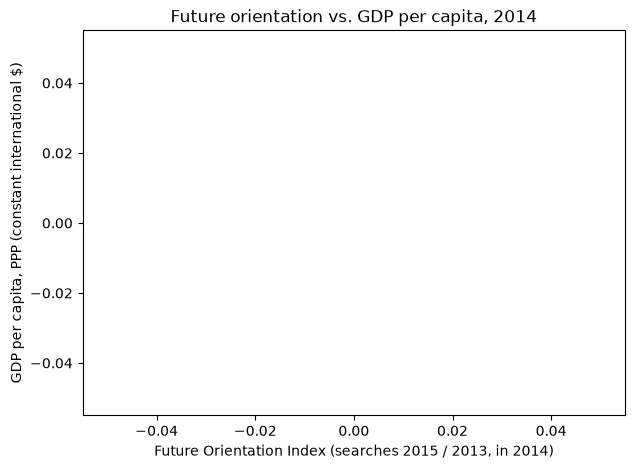

In [10]:
# Your Code goes here!
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))
plt.scatter(merged["FOI"], merged["GDP"])
plt.xlabel("Future Orientation Index (searches 2015 / 2013, in 2014)")
plt.ylabel("GDP per capita, PPP (constant international $)")
plt.title("Future orientation vs. GDP per capita, 2014")
plt.show()


## 3.2 Measure Pearson’s correlation

In the following chunk, calculate Pearson’s correlation coefficient between GDP and FOI.

For this you can use the [`pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) method of `scipy`.  
Also write in a brief comment what this correlation coefficient means for the relationship of the future orientation and GDP of a country. 

In [11]:
# Your Code goes here!
r, p = stats.pearsonr(merged["FOI"], merged["GDP"])
print(f"r = {r:.2f}, p = {p:.4f}")


ValueError: `x` and `y` must have length at least 2.

# To learn more
### Check robustness
* What result do you get if you use other years? What if you choose one of the earliest years in Google trends?
* How do results change if you use a different threshod instead of 5 Million Internet users?
    
### Test other hypotheses
* Is future orientation generating wealth? Or is wealth enabling to look more to the future?
* Is the FOI really measuring orientation to the future? Could it be something else?

# Task 2: 

## Using Google Trends data to model Flu Trends

## Tasks
Google once proposed that they could predict flu waves using their search terms. We want to test if that's true. To achieve this, we use a dataset of Google search terms for flu and one for the flu cases in America. With those, we try to calculate a correlation between them.

### Install requirements. 

The following cell contains all the necessary dependencies needed for this task. If you run the cell everything will be installed.  
* [`pytrends`]((https://pypi.org/project/pytrends/)
* [`requests`]
* [`statsmodels`]

In [ ]:
! pip install -U pytrends
! pip install requests
! pip install statsmodels


## 1.1 Get weekly Google Trends data concerning the Flu/Influenza virus
Normally you could use the TrendReq class from the pytrends library to access google search trends. Because this can be unreliable, we already uploaded a dataset 'flu_interest_trends'  you can use instead. If you want, you can also try to get the data directly from the API.  
- Either read the `flu_interest_trends.csv` dataset and store it as a [pandas](https://pypi.org/project/pandas/) dataframe or request the data using the [TrendReq](https://github.com/GeneralMills/pytrends) class.

In [1]:
# Your Code goes here!
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
 
flu = pd.read_csv("flu_interest_trends.csv", parse_dates=["date"])
flu = flu.rename(columns={"/m/0cycc": "flu_interest"})
print(flu.shape)
flu.head()


(261, 3)


,date,flu_interest,isPartial
0,2014-01-05,0,False
1,2014-01-12,0,False
2,2014-01-19,0,False
3,2014-01-26,0,False
4,2014-02-02,0,False


# 2 US National data

## Get data regarding the occurance of Influenza like Illnesses in the US

In the `Excercise 1` folder you will find a file named `ILINet.csv`, which contains data regarding the occurance of Influenza like Illnesses in the US. You can also find the data and the corresponding [documentation](https://gis.cdc.gov/grasp/fluview/FluViewPhase2QuickReferenceGuide.pdf) on the CDC's [FluView interactive dashboard](https://gis.cdc.gov/grasp/fluview/fluportaldashboard.html).
<br>
- Read the csv file, and store it as a [pandas](https://pypi.org/project/pandas/) dataframe. You might need to use the `skiprows` argument of the `read_csv` method to be able to load the data correctly.
- Select the columns named `YEAR`, `WEEK`, and `% WEIGHTED ILI` which will be needed for our analysis. Additionally, drop the rows which store observations from before 2014, or later than 2018.

In [2]:
# Your Code goes here!
ili = pd.read_csv("ILINet.csv", skiprows=1)
ili = ili[["YEAR", "WEEK", "% WEIGHTED ILI"]]
ili = ili[(ili["YEAR"] >= 2014) & (ili["YEAR"] <= 2018)].reset_index(drop=True)
print(ili.shape)
ili.head()

(261, 3)


,YEAR,WEEK,% WEIGHTED ILI
0,2014,1,4.28195
1,2014,2,3.56288
2,2014,3,3.36378
3,2014,4,3.39659
4,2014,5,3.11922


# 3 Testing the correlation between flu interest and US National data

# 3.1 Visualize flu interest vs US National data

Now that you have the US National data regarding the occurance of Influenza like Illnesses in the US, you can make a scatter plot of `flu interest` vs `% WEIGHTED ILI`.

For this you can use the [`scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) method of `matplotlib`.

In [3]:
# Your Code goes here!
df = pd.concat([flu[["date", "flu_interest"]], ili], axis=1)
df.head()


,date,flu_interest,YEAR,WEEK,% WEIGHTED ILI
0,2014-01-05,0,2014,1,4.28195
1,2014-01-12,0,2014,2,3.56288
2,2014-01-19,0,2014,3,3.36378
3,2014-01-26,0,2014,4,3.39659
4,2014-02-02,0,2014,5,3.11922


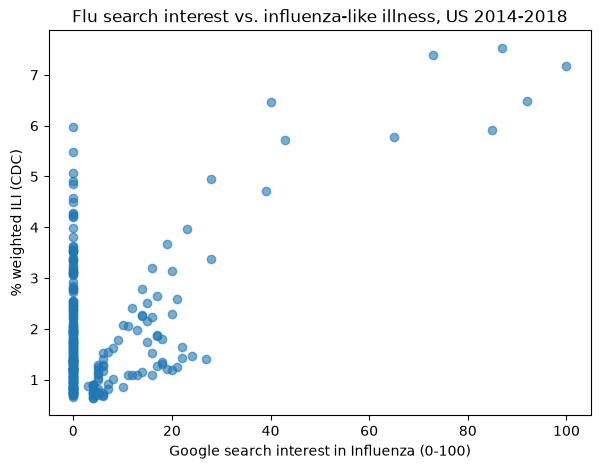

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(df["flu_interest"], df["% WEIGHTED ILI"], alpha=0.6)
plt.xlabel("Google search interest in Influenza (0-100)")
plt.ylabel("% weighted ILI (CDC)")
plt.title("Flu search interest vs. influenza-like illness, US 2014-2018")
plt.show()


## 3.2 Measure Pearson’s correlation

In the following chunk, calculate Pearson’s correlation coefficient between `flu interest` and `% WEIGHTED ILI`.

For this you can use the [`pearsonr`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) method of `scipy`.

In [5]:
# Your Code goes here!
r, p = stats.pearsonr(df["flu_interest"], df["% WEIGHTED ILI"])
print(f"r = {r:.3f}, p = {p:.2e}")



r = 0.560, p = 6.14e-23


## 3.3 Measure correlation after shuffling


Now we want to test if such a correlation could also appear by chance. For this, we shuffle the flue interest column and match it with a random search count. With that, we again calculate the correlation and compare it to the original.

For the shuffeling you can use `pandas` [`sample`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sample.html) method with `frac` set to 1.

This test shows you if the correlation could also happen by random chance.

In [6]:
# Your Code goes here!
shuffled = df["flu_interest"].sample(frac=1).reset_index(drop=True)
r_shuffled, p_shuffled = stats.pearsonr(shuffled, df["% WEIGHTED ILI"])
print(f"shuffled r = {r_shuffled:.3f}  (original r = {r:.3f})")


shuffled r = -0.002  (original r = 0.560)


Repeat the calculation with 1000 permutations and plot the histogram of the resulting values. Add a line with the value of the correlation without permutation. Is it far or close to the permuted values?

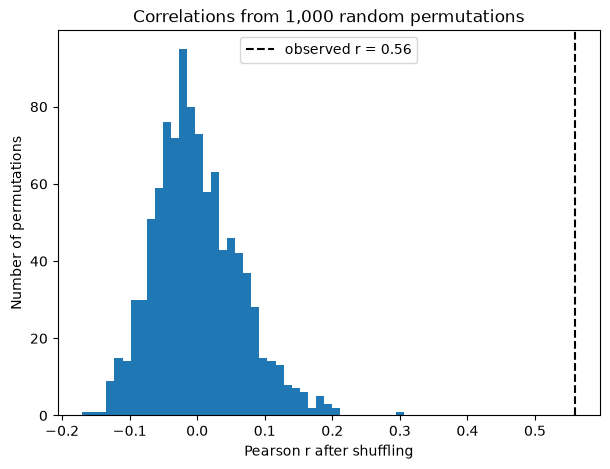

In [7]:
# Your Code goes here!
perm_rs = []
for i in range(1000):
    shuffled = df["flu_interest"].sample(frac=1).reset_index(drop=True)
    perm_rs.append(stats.pearsonr(shuffled, df["% WEIGHTED ILI"])[0])
 
plt.figure(figsize=(7, 5))
plt.hist(perm_rs, bins=40)
plt.axvline(r, color="black", linestyle="--", label=f"observed r = {r:.2f}")
plt.xlabel("Pearson r after shuffling")
plt.ylabel("Number of permutations")
plt.title("Correlations from 1,000 random permutations")
plt.legend()
plt.show()


### To learn more

#### Prediction
* Download the Google Trends data for 2019, and use your models to predict the values of `% WEIGHTED ILI`.
* Do the models make good predictions? Which model performs better?